In [51]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


c:\Users\leand\Documents\mecai-26-prob-estat\.venv\Scripts\python.exe: No module named pip


In [52]:
import pandas as pd
from pathlib import Path

# ==============================================================================
# 0. CONFIGURAÇÃO DE CAMINHOS
# ==============================================================================
caminho_raiz = Path.cwd().resolve()
while not (caminho_raiz / "data").exists() and caminho_raiz.name != "":
    caminho_raiz = caminho_raiz.parent

# AJUSTE: Apontamento corrigido para o arquivo .parquet atualizado
caminho_producao = caminho_raiz / "data" / "interim" / "safra" / "producao_feijao_tons.parquet"
caminho_demanda = caminho_raiz / "data" / "interim" / "safra" / "dados_demanda.xlsx"
caminho_distancia = caminho_raiz / "data" / "interim" / "safra" / "dados_distancia.xlsx"
caminho_final = caminho_raiz / "data" / "processed" / "consolidado" / "painel_feijao_consolidado.parquet" 

# ==============================================================================
# 1. LEITURA E PADRONIZAÇÃO DE NOMES
# ==============================================================================
# AJUSTE: Utilização do método de leitura de Parquet nativo
df_producao = pd.read_parquet(caminho_producao)

df_demanda = pd.read_excel(caminho_demanda, engine='openpyxl')
df_distancia = pd.read_excel(caminho_distancia, engine='openpyxl')

# Limpeza de espaços invisíveis e conversão para letras minúsculas
df_producao.columns = df_producao.columns.astype(str).str.strip().str.lower()
df_distancia.columns = df_distancia.columns.astype(str).str.strip().str.lower()
df_demanda.columns = df_demanda.columns.astype(str).str.strip().str.lower()

# Garantia de tipagem temporal (evita falhas silenciosas de merge int32 vs float64)
df_producao['ano'] = df_producao['ano'].astype(int)
df_producao['mes'] = df_producao['mes'].astype(int)

# ==============================================================================
# 2. MODELAGEM GRAVITACIONAL
# ==============================================================================
BETA = 1.0  

# Cruzando 'uf' (da produção) com 'estado_origem' (da distância)
df_matriz = df_producao.merge(df_distancia, left_on='uf', right_on='estado_origem', how='inner')
df_matriz = df_matriz.merge(df_demanda, on='estado_destino', how='left')

# Fator gravitacional
df_matriz['peso_gravitacional'] = df_matriz['demanda_ton_mes'] / (df_matriz['distancia_km'] ** BETA)

# A normalização deve agrupar por quem enviou
df_matriz['soma_pesos_origem'] = df_matriz.groupby(['uf', 'ano', 'mes'])['peso_gravitacional'].transform('sum')
df_matriz['fracao_alocada'] = df_matriz['peso_gravitacional'] / df_matriz['soma_pesos_origem']

# Multiplicação final pelo volume 
df_matriz['volume_enviado_ton'] = df_matriz['quantidade_tons'] * df_matriz['fracao_alocada']

# Agrupamento da oferta que chegou no destino (mantendo a flag is_estimado)
df_oferta_local = df_matriz.groupby(['estado_destino', 'ano', 'mes', 'is_estimado'])['volume_enviado_ton'].sum().reset_index()

# ==============================================================================
# 3. CONVERSÃO DE SIGLAS E INTEGRAÇÃO AO PARQUET
# ==============================================================================
mapa_uf = {
    'sergipe': 'SE', 'minas_gerais': 'MG', 'distrito_federal': 'DF',
    'parana': 'PR', 'santa_catarina': 'SC', 'ceara': 'CE',
    'paraiba': 'PB', 'rio_grande_do_norte': 'RN', 'rio_grande_do_sul': 'RS',
    'pernambuco': 'PE', 'rio_de_janeiro': 'RJ', 'bahia': 'BA',
    'sao_paulo': 'SP', 'goias': 'GO', 'espirito_santo': 'ES',
    'para': 'PA', 'mato_grosso': 'MT', 'piaui': 'PI'
}

# Criamos a coluna UF com as siglas oficiais e renomeamos o volume
df_oferta_local['uf_destino'] = df_oferta_local['estado_destino'].map(mapa_uf)
df_oferta_local.rename(columns={'volume_enviado_ton': 'oferta_interna_estimada_ton'}, inplace=True)

# Lemos o Parquet consolidado
df_final = pd.read_parquet(caminho_final)
df_final['ano'] = df_final['data_referencia'].dt.year
df_final['mes'] = df_final['data_referencia'].dt.month

# NOVO: Purga definitiva de duplicações de linhas geradas por execuções anteriores
df_final = df_final.drop_duplicates(subset=['data_referencia', 'uf'], keep='first')

# Se as colunas já existirem no parquet, removemos antes do merge para reescrever limpo
for col in ['oferta_interna_estimada_ton', 'is_estimado']:
    if col in df_final.columns:
        df_final.drop(columns=[col], inplace=True)

# Cruzamento com a sigla uf trazendo o volume e a flag
df_final = df_final.merge(
    df_oferta_local[['uf_destino', 'ano', 'mes', 'oferta_interna_estimada_ton', 'is_estimado']], 
    left_on=['uf', 'ano', 'mes'], 
    right_on=['uf_destino', 'ano', 'mes'],
    how='left'
)

# Drop da coluna extra de cruzamento
df_final.drop(columns=['uf_destino'], inplace=True)

# Preenche os vazios gerados pelo left join
df_final['oferta_interna_estimada_ton'] = round(df_final['oferta_interna_estimada_ton'].fillna(0), 0)

# Preenche os meses sem oferta (NaN) na flag is_estimado usando a regra temporal
df_final['is_estimado'] = df_final['is_estimado'].fillna(
    (df_final['ano'] < 2006) | ((df_final['ano'] == 2006) & (df_final['mes'] < 9))
)

df_final.to_parquet(caminho_final, index=False)
print("Matriz O-D incorporada com sucesso.")

Matriz O-D incorporada com sucesso.


In [53]:
display(df_final[['data_referencia', 'capital', 'uf', 'oferta_interna_estimada_ton']].sample(60))

,data_referencia,capital,uf,oferta_interna_estimada_ton
145,2016-02-01,Brasília,DF,4567.0
4169,2012-09-01,Salvador,BA,45542.0
4282,2022-02-01,Salvador,BA,5389.0
672,2014-11-01,Belo Horizonte,MG,12218.0
4237,2018-05-01,Salvador,BA,55983.0
1352,2026-05-01,São Paulo,SP,142839.0
1628,2004-03-01,Curitiba,PR,15954.0
2302,2015-03-01,Porto Alegre,RS,6138.0
2525,2011-03-01,Belém,PA,1575.0
1183,2012-04-01,São Paulo,SP,66508.0


In [54]:
# ==============================================================================
# 5. SALVAR DATASET FINAL EM FORMATO EXCEL (.xlsx)
# ==============================================================================
# Define o caminho para o arquivo Excel na mesma pasta do Parquet
caminho_excel = caminho_raiz / "data" / "processed" / "consolidado" / "painel_feijao_consolidado.xlsx"

print("Salvando arquivo Excel... (isso pode levar alguns instantes dependendo do tamanho da base)")

# Exporta o dataframe para Excel usando o openpyxl
df_final.to_excel(caminho_excel, index=False, engine='openpyxl')

print(f"Arquivo Excel salvo com sucesso em:\n{caminho_excel}")

Salvando arquivo Excel... (isso pode levar alguns instantes dependendo do tamanho da base)
Arquivo Excel salvo com sucesso em:
C:\Users\leand\Documents\mecai-26-prob-estat\data\processed\consolidado\painel_feijao_consolidado.xlsx


,Média,Mediana,Desvio Padrão,Variância
0,266297.196296,239202.5,149314.700821,2.229488e+10


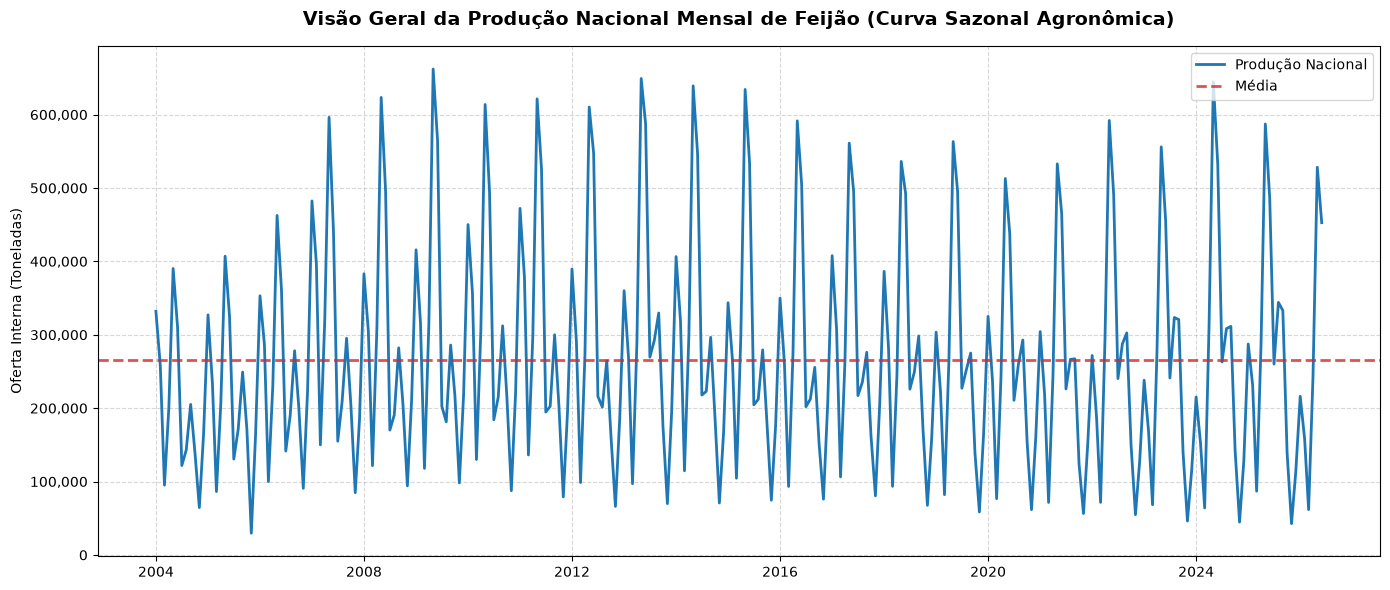

In [55]:
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
from IPython.display import display

# ==============================================================================
# 1. EXTRAÇÃO DOS DADOS (LINHA PRINCIPAL)
# ==============================================================================
linha_principal = duckdb.sql("""
    SELECT 
        CAST(data_referencia AS DATE) AS data,
        SUM(oferta_interna_estimada_ton) AS oferta
    FROM df_final
    WHERE CAST(data_referencia AS DATE) <= '2026-06-01'
    GROUP BY CAST(data_referencia AS DATE)
    ORDER BY data ASC;
""").df()

linha_principal.set_index('data', inplace=True)

# ==============================================================================
# 2. ESTATÍSTICAS DESCRITIVAS
# ==============================================================================
descritivas = duckdb.sql("""
    WITH producao_nacional AS (
         SELECT
             CAST(data_referencia AS DATE) AS data,
             SUM(oferta_interna_estimada_ton) AS oferta
         FROM df_final
         WHERE CAST(data_referencia AS DATE) <= '2026-06-01'
         GROUP BY CAST(data_referencia AS DATE)
    )
    SELECT 
        AVG(oferta) AS "Média",
        PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY oferta) AS "Mediana",
        STDDEV(oferta) AS "Desvio Padrão",
        VARIANCE(oferta) AS "Variância"
    FROM producao_nacional;                    
""").df()

display(descritivas)

media = descritivas["Média"].iloc[0]
mediana = descritivas["Mediana"].iloc[0]
desvio_padrao = descritivas["Desvio Padrão"].iloc[0]
variancia = descritivas["Variância"].iloc[0]

# ==============================================================================
# 3. PLOTAGEM DO GRÁFICO
# ==============================================================================
fig, ax = plt.subplots(figsize=(14,6))

# A linha principal mostrará a nova sazonalidade (Picos na colheita e vales em Julho)
ax.plot(linha_principal.index, linha_principal["oferta"], color='#1f77b4', linewidth=2, label="Produção Nacional")

ax.axhline(media, color="#d62728", linestyle="--", linewidth=2, alpha=0.8, label="Média")
# ax.axhline(mediana, color="#2ca02c", linestyle=":", linewidth=2, alpha=0.8, label="Mediana")

y_topo = ax.get_ylim()[1] 

# Proteção para renderizar os eventos caso a lista exista
if 'choques' in locals() or 'choques' in globals():
    for choque in choques:
        data_choque = pd.to_datetime(choque["data"])
        cor = choque["cor"]
        ax.axvline(x=data_choque, color=cor, linestyle=":", linewidth=1.5, zorder=2)
        ax.text(
            x=data_choque,
            y=y_topo * 0.95,
            s=choque["texto"],
            color=cor,
            fontsize=9,
            ha="center",
            va="top",
            zorder=4,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor=cor, alpha=0.9)
        )
    
ax.set_title('Visão Geral da Produção Nacional Mensal de Feijão (Curva Sazonal Agronômica)',
             fontweight='bold',
             fontsize=14,
             pad=15)
ax.set_ylabel('Oferta Interna (Toneladas)')

ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()

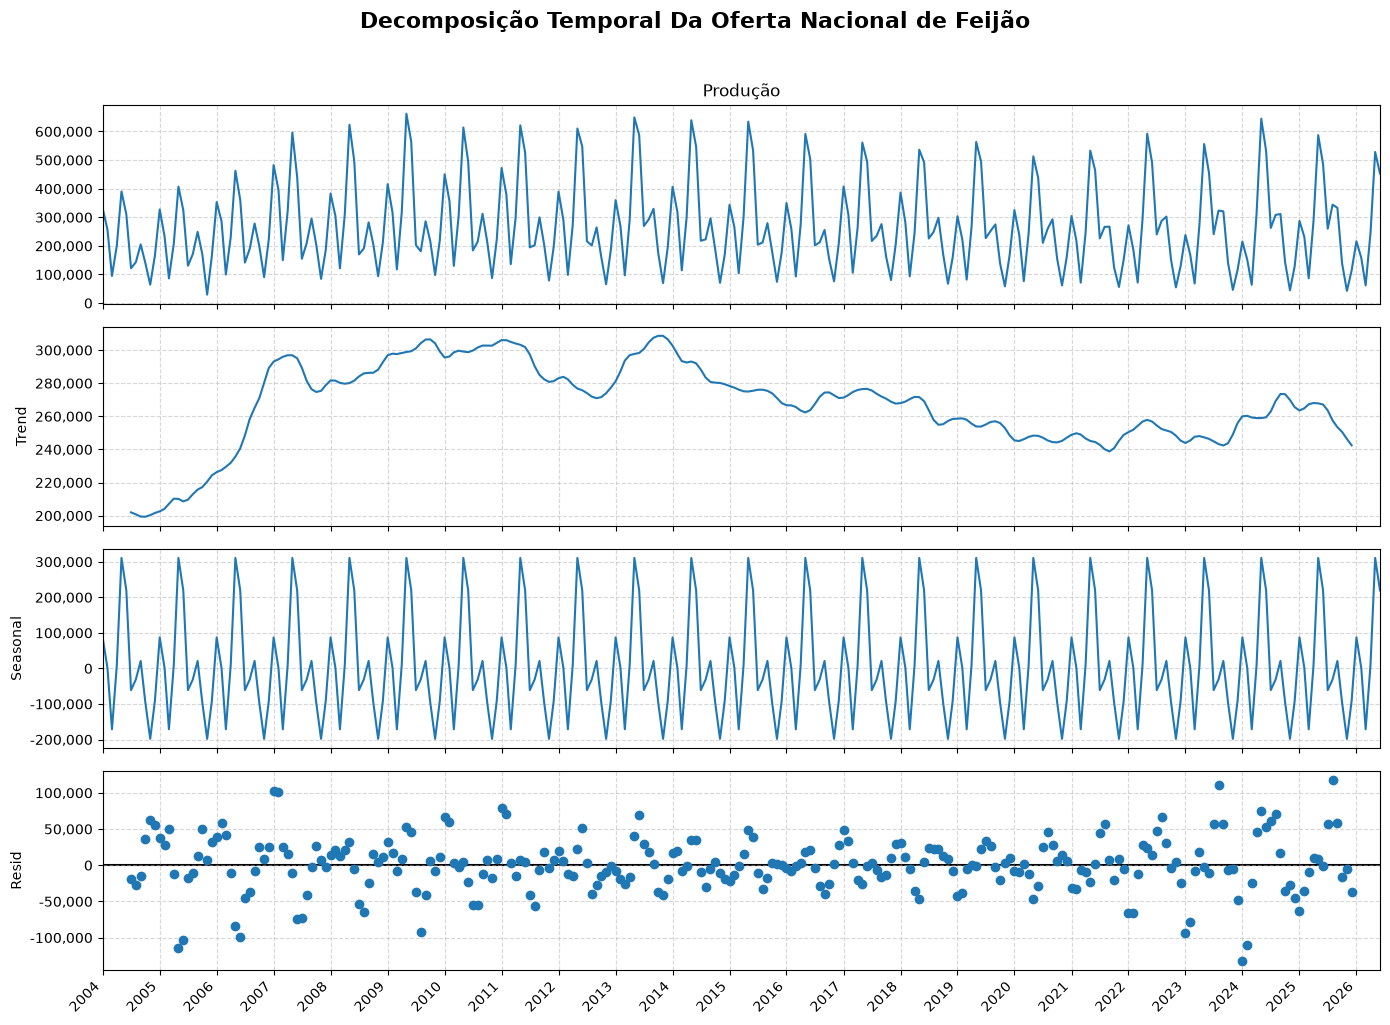

In [56]:
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import seasonal_decompose

# ==============================================================================
# 1. PREPARAÇÃO DA SÉRIE TEMPORAL NO DUCKDB
# ==============================================================================
# Ajuste: CAST da data_referencia (nativo) e tabela baseada no df_final
serie = duckdb.sql("""
    SELECT
        CAST(data_referencia AS DATE) AS "Data",
        SUM(oferta_interna_estimada_ton) AS "Produção"
    FROM df_final
    WHERE CAST(data_referencia AS DATE) <= '2026-06-01'
    GROUP BY CAST(data_referencia AS DATE)
    ORDER BY "Data" ASC;
""").df()

serie.set_index('Data', inplace=True)

# Garante que o índice é datetime (necessário para o seasonal_decompose)
serie.index = pd.to_datetime(serie.index)

# ==============================================================================
# 2. DECOMPOSIÇÃO TEMPORAL (STATSMODELS)
# ==============================================================================
decomposicao = seasonal_decompose(
    serie["Produção"],
    model="additive", 
    period=12,
)

fig = decomposicao.plot()
fig.set_size_inches(14,10)
fig.suptitle(
    "Decomposição Temporal Da Oferta Nacional de Feijão",
    fontweight='bold', 
    fontsize=16, 
    y=1.02
)

axes = fig.get_axes()

# ==============================================================================
# 3. RENDERIZAÇÃO DOS CHOQUES E FORMATAÇÃO
# ==============================================================================
# Proteção contra lista de choques não declarada no escopo
if 'choques' in locals() or 'choques' in globals():
    for choque in choques:
        data_choque = pd.to_datetime(choque["data"])
        cor = choque["cor"]
        texto = choque["texto"]
        
        for ax in axes:
            ax.axvline(x=data_choque, color=cor, linestyle=":", linewidth=2, zorder=1)
            
        y_topo_primeiro_grafico = axes[0].get_ylim()[1]
        axes[0].text(
            x=data_choque, 
            y=y_topo_primeiro_grafico * 0.95,
            s=texto,
            color=cor,
            fontsize=9,
            ha="center",
            va="top",
            zorder=4,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor=cor, alpha=0.9)
        )

for ax in axes:
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ',')))
        
axes[3].xaxis.set_major_locator(mdates.YearLocator(1))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
# Rotaciona os anos para caberem sem sobreposição
plt.setp(axes[3].xaxis.get_majorticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.show()

C:\Users\leand\AppData\Local\Temp\ipykernel_15268\2039952611.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='mes', y='oferta', data=df_boxplot, palette='viridis',


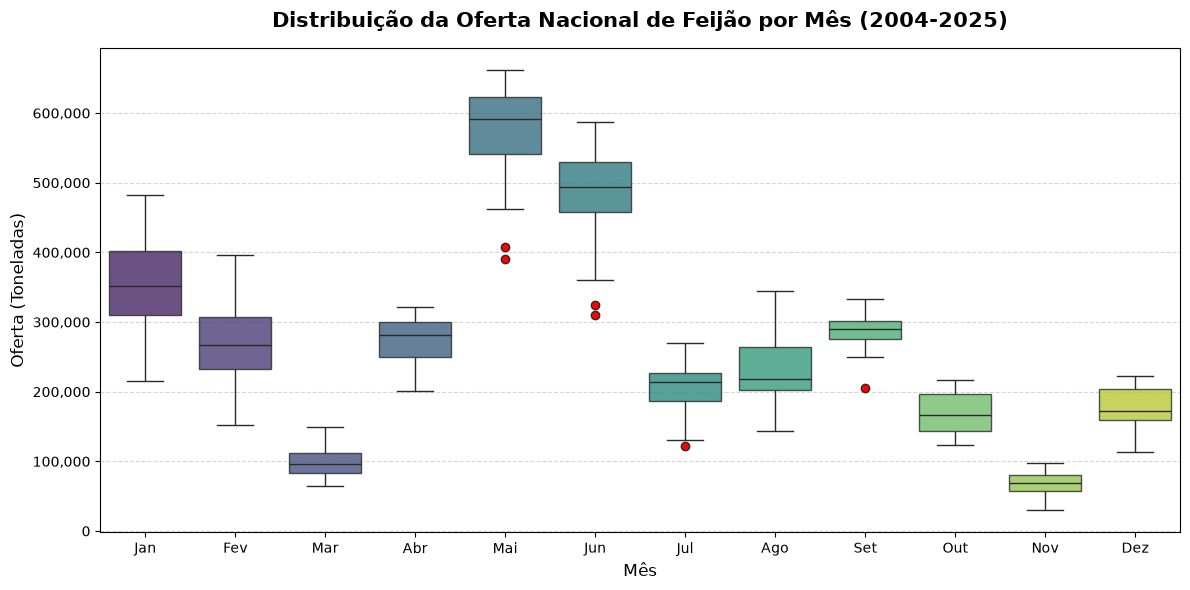

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
import duckdb

# Busca os dados mes a mes
df_boxplot = duckdb.sql("""
    SELECT 
        mes, 
        SUM(oferta_interna_estimada_ton) as oferta
    FROM df_final
    WHERE ano <= 2025
    GROUP BY ano, mes
""").df()

# Nomes dos meses para o eixo X
mapa_meses = {1:'Jan', 2:'Fev', 3:'Mar', 4:'Abr', 5:'Mai', 6:'Jun', 
              7:'Jul', 8:'Ago', 9:'Set', 10:'Out', 11:'Nov', 12:'Dez'}
df_boxplot['Nome_Mes'] = df_boxplot['mes'].map(mapa_meses)

plt.figure(figsize=(12, 6))
sns.boxplot(x='mes', y='oferta', data=df_boxplot, palette='viridis', 
            boxprops=dict(alpha=0.8), flierprops=dict(markerfacecolor='r', marker='o'))

# Formatação
plt.title('Distribuição da Oferta Nacional de Feijão por Mês (2004-2025)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Mês', fontsize=12)
plt.ylabel('Oferta (Toneladas)', fontsize=12)
plt.xticks(ticks=range(0,12), labels=mapa_meses.values())
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: format(int(x), ',')))
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

<Axes: ylabel='Resid'>

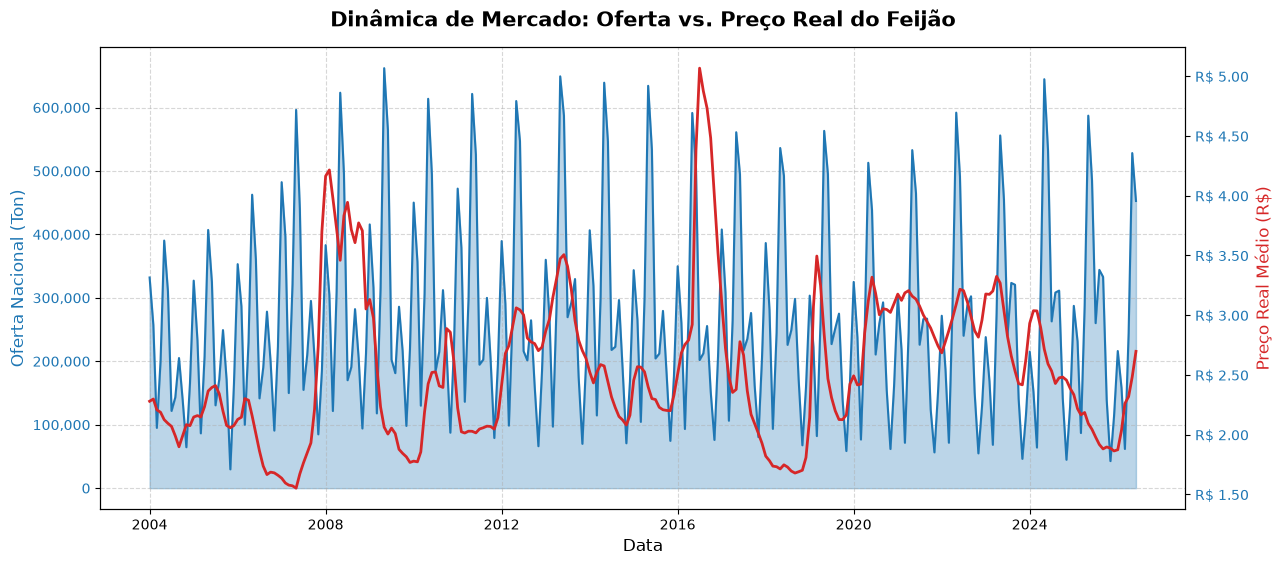

In [58]:
import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import StrMethodFormatter

# Extração e agrupamento
df_tesoura = duckdb.sql("""
    SELECT 
        CAST(data_referencia AS DATE) AS data,
        SUM(oferta_interna_estimada_ton) AS oferta,
        AVG(preco_real_feijao) AS preco_medio
    FROM df_final
    WHERE CAST(data_referencia AS DATE) <= '2026-06-01'
    GROUP BY CAST(data_referencia AS DATE)
    ORDER BY data ASC
""").df()

fig, ax1 = plt.subplots(figsize=(14, 6))

# Eixo 1: Oferta (em barras azuis claras ou linha)
cor_oferta = '#1f77b4'
ax1.set_xlabel('Data', fontsize=12)
ax1.set_ylabel('Oferta Nacional (Ton)', color=cor_oferta, fontsize=12)
ax1.fill_between(df_tesoura['data'], df_tesoura['oferta'], color=cor_oferta, alpha=0.3, label='Oferta (Ton)')
ax1.plot(df_tesoura['data'], df_tesoura['oferta'], color=cor_oferta, linewidth=1.5)
ax1.tick_params(axis='y', labelcolor=cor_oferta)
ax1.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

# Eixo 2: Preço (em linha vermelha)
ax2 = ax1.twinx()  
cor_preco = '#d62728'
ax2.set_ylabel('Preço Real Médio (R$)', color=cor_preco, fontsize=12)
ax2.plot(df_tesoura['data'], df_tesoura['preco_medio'], color=cor_preco, linewidth=2, label='Preço Real')
ax2.tick_params(axis='y', labelcolor=cor_oferta)
ax2.yaxis.set_major_formatter(StrMethodFormatter('R$ {x:,.2f}'))

# Formatação
plt.title('Dinâmica de Mercado: Oferta vs. Preço Real do Feijão', fontsize=15, fontweight='bold', pad=15)
ax1.grid(True, linestyle="--", alpha=0.5)

# Unindo as legendas
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax

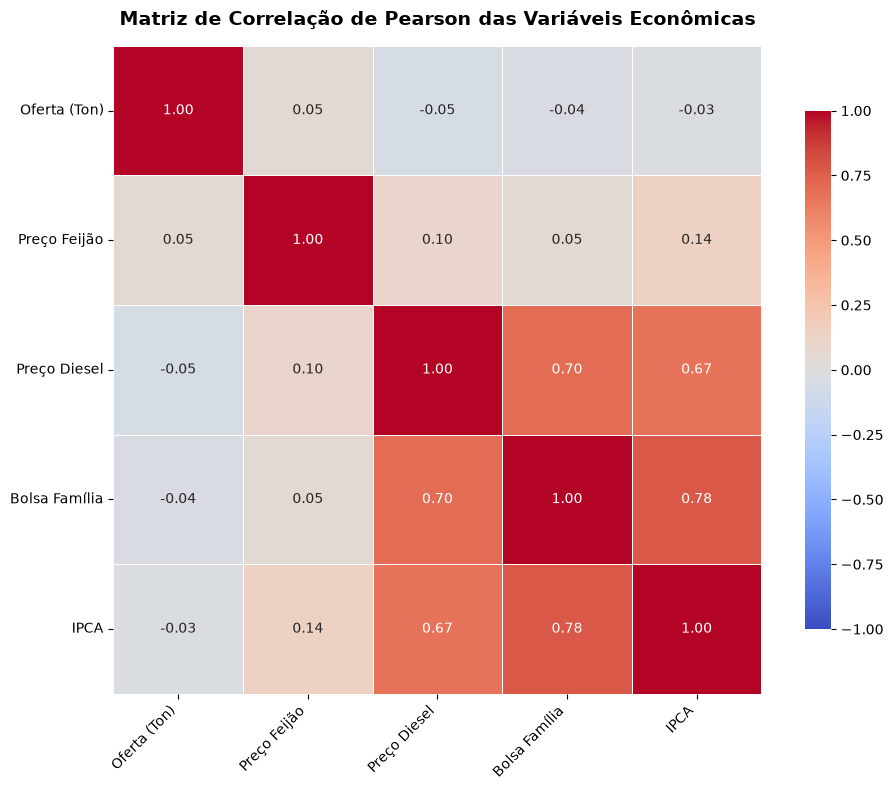

In [59]:
import seaborn as sns
import matplotlib.pyplot as plt
import duckdb

# Extraindo as variáveis numéricas chave
df_corr = duckdb.sql("""
    SELECT 
        SUM(oferta_interna_estimada_ton) AS "Oferta (Ton)",
        AVG(preco_real_feijao) AS "Preço Feijão",
        AVG(venda_real_diesel_media_geral) AS "Preço Diesel",
        AVG(valor_repassado_pbf_real) AS "Bolsa Família",
        AVG(ipca_indice) AS "IPCA"
    FROM df_final
    WHERE CAST(data_referencia AS DATE) <= '2026-06-01'
    GROUP BY CAST(data_referencia AS DATE)
""").df()

# Calculando a matriz de correlação de Pearson
matriz_correlacao = df_corr.corr()

plt.figure(figsize=(10, 8))
# Cria o mapa de calor
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, 
            square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Matriz de Correlação de Pearson das Variáveis Econômicas', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

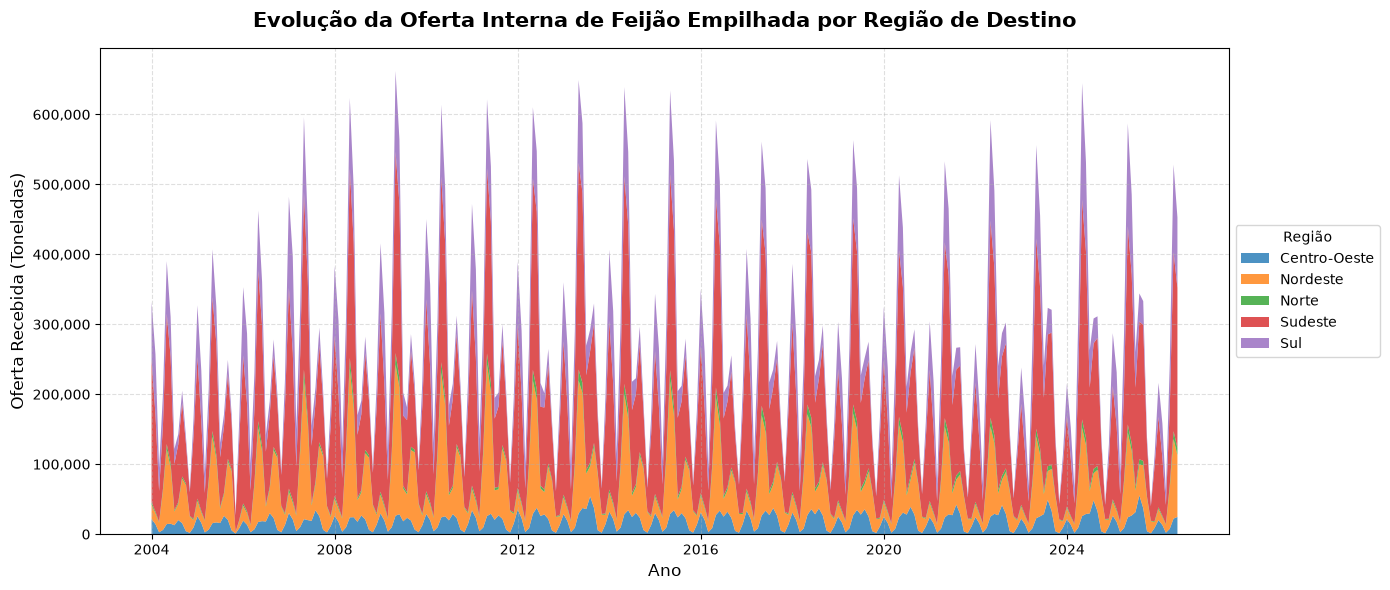

In [60]:
import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Extrai os dados agrupados por data e região
df_regional = duckdb.sql("""
    SELECT 
        CAST(data_referencia AS DATE) AS data,
        regiao,
        SUM(oferta_interna_estimada_ton) AS oferta
    FROM df_final
    WHERE CAST(data_referencia AS DATE) <= '2026-06-01'
        AND regiao IS NOT NULL
    GROUP BY CAST(data_referencia AS DATE), regiao
    ORDER BY data ASC
""").df()

# Pivoteia a tabela para ter as regiões como colunas (formato exigido pelo stackplot)
df_pivot = df_regional.pivot(index='data', columns='regiao', values='oferta').fillna(0)

fig, ax = plt.subplots(figsize=(14, 6))

# Criação da área empilhada
ax.stackplot(df_pivot.index, df_pivot.T, labels=df_pivot.columns, alpha=0.8, 
             colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])

ax.set_title('Evolução da Oferta Interna de Feijão Empilhada por Região de Destino', 
             fontsize=15, fontweight='bold', pad=15)
ax.set_ylabel('Oferta Recebida (Toneladas)', fontsize=12)
ax.set_xlabel('Ano', fontsize=12)

ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(True, linestyle="--", alpha=0.4)

# Posiciona a legenda fora do gráfico para não tampar os dados
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), title="Região")

plt.tight_layout()
plt.show()